In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA_PATH = Path("data/processed/INX_employee_performance_processed.csv")
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (1200, 28)


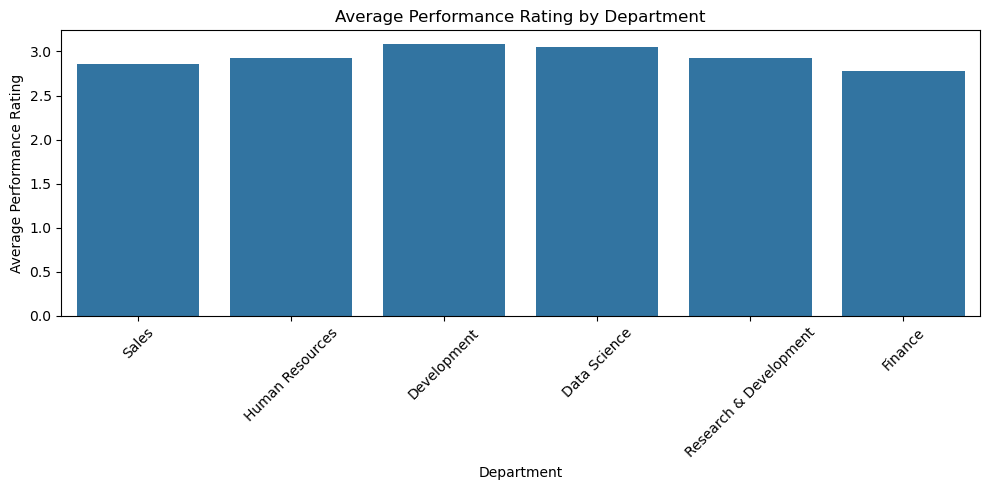

In [2]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="EmpDepartment",
    y="PerformanceRating",
    errorbar=None
)

plt.title("Average Performance Rating by Department")
plt.xlabel("Department")
plt.ylabel("Average Performance Rating")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

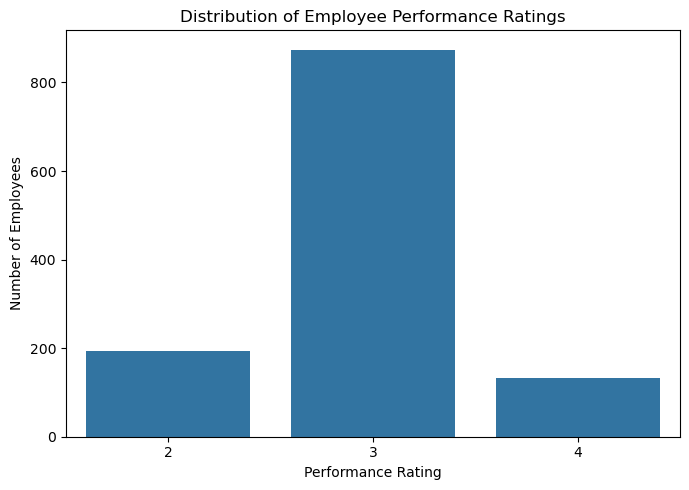

In [3]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="PerformanceRating"
)

plt.title("Distribution of Employee Performance Ratings")
plt.xlabel("Performance Rating")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()

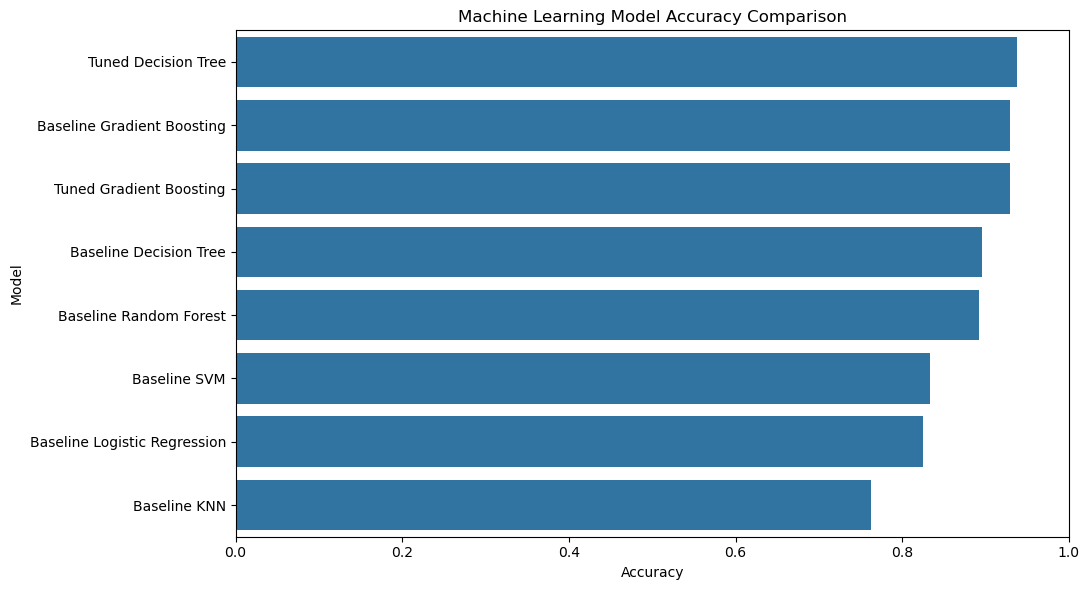

In [4]:
model_results = pd.DataFrame({
    "Model": [
        "Tuned Decision Tree",
        "Baseline Gradient Boosting",
        "Tuned Gradient Boosting",
        "Baseline Decision Tree",
        "Baseline Random Forest",
        "Baseline Logistic Regression",
        "Baseline SVM",
        "Baseline KNN"
    ],
    "Accuracy": [
        0.9375, 0.9292, 0.9292, 0.8958,
        0.8917, 0.8250, 0.8333, 0.7625
    ],
    "Macro F1": [
        0.8996, 0.8856, 0.8856, 0.8434,
        0.7982, 0.7157, 0.6891, 0.5313
    ],
    "Macro Recall": [
        0.8661, 0.8623, 0.8623, 0.8205,
        0.7379, 0.6780, 0.6182, 0.4890
    ]
})

accuracy_results = model_results.sort_values(
    by="Accuracy", ascending=False
)

plt.figure(figsize=(11, 6))
sns.barplot(data=accuracy_results, x="Accuracy", y="Model")
plt.title("Machine Learning Model Accuracy Comparison")
plt.xlabel("Accuracy")
plt.ylabel("Model")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

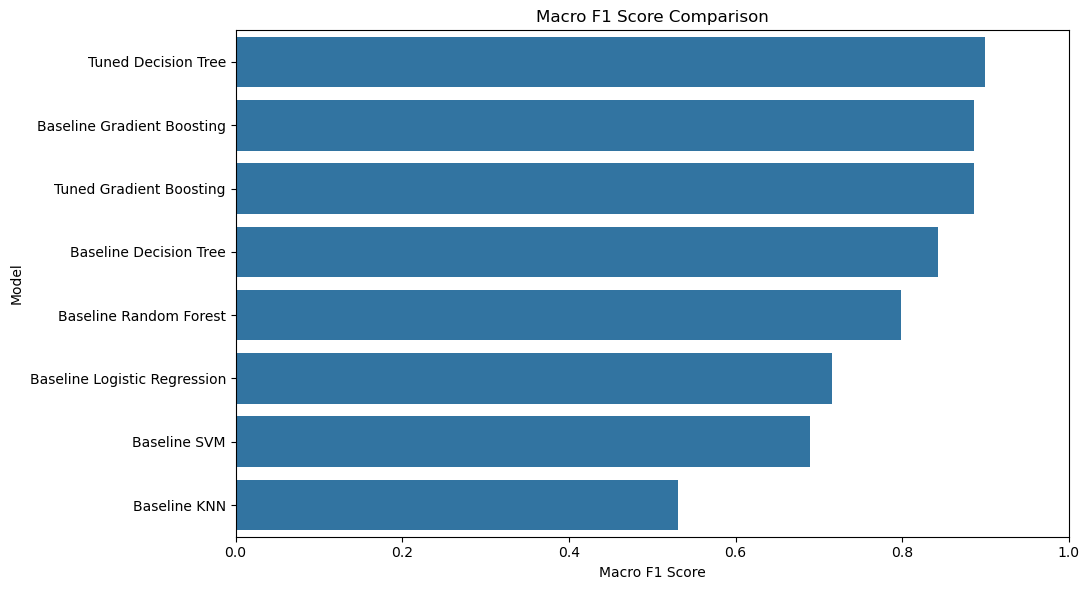

In [5]:
f1_results = model_results.sort_values(
    by="Macro F1", ascending=False
)

plt.figure(figsize=(11, 6))
sns.barplot(data=f1_results, x="Macro F1", y="Model")
plt.title("Macro F1 Score Comparison")
plt.xlabel("Macro F1 Score")
plt.ylabel("Model")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

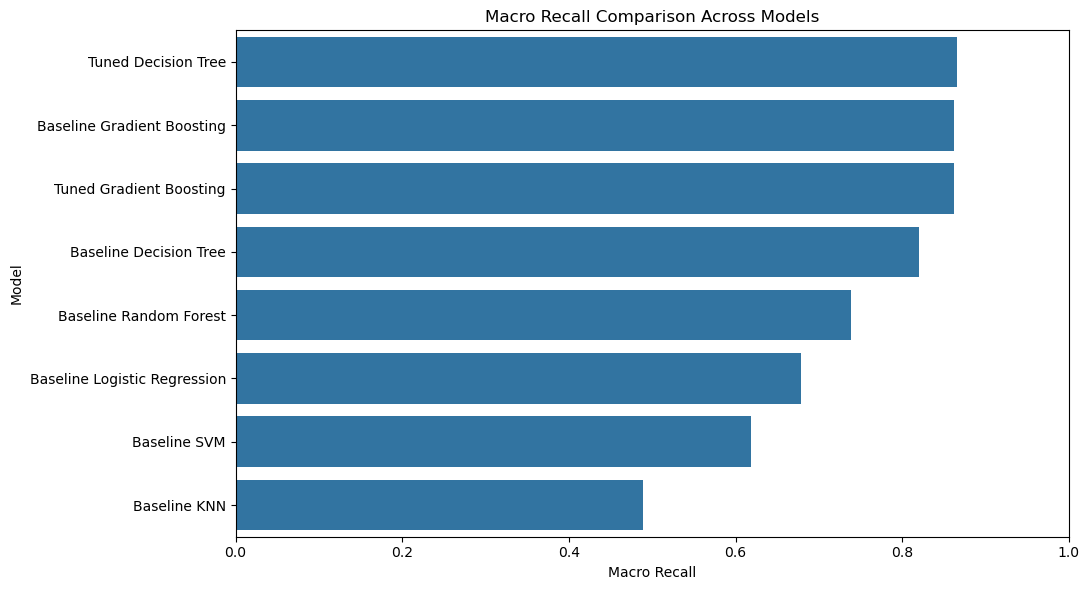

In [6]:
recall_results = model_results.sort_values(
    by="Macro Recall", ascending=False
)

plt.figure(figsize=(11, 6))
sns.barplot(data=recall_results, x="Macro Recall", y="Model")
plt.title("Macro Recall Comparison Across Models")
plt.xlabel("Macro Recall")
plt.ylabel("Model")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

In [7]:
import joblib

MODEL_PATH = Path("src/models/final_employee_performance_model.pkl")
model = joblib.load(MODEL_PATH)

print("Model loaded successfully!")
print("Model type:", type(model).__name__)

Model loaded successfully!
Model type: Pipeline


In [8]:
print("Pipeline steps:")

for name, step in model.named_steps.items():
    print(name, ":", type(step).__name__)

Pipeline steps:
preprocessor : ColumnTransformer
classifier : DecisionTreeClassifier


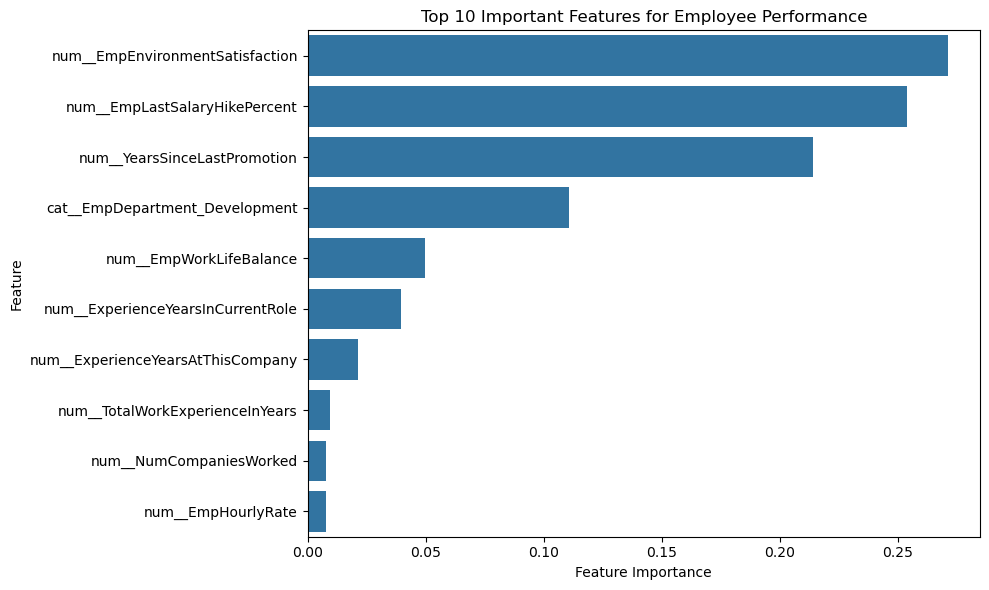

In [9]:
# Extract Decision Tree from the Pipeline
tree_model = model.named_steps["classifier"]

# Get feature importance values
importance_values = tree_model.feature_importances_

# Get feature names after preprocessing
feature_names = model.named_steps["preprocessor"].get_feature_names_out()

# Create DataFrame
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

# Show top 10 important features
importance_df = importance_df.sort_values(
    by="Importance", ascending=False
).head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features for Employee Performance")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## Visualization Summary

1. The Tuned Decision Tree achieved the highest accuracy of 93.75%.
2. The Tuned Decision Tree achieved the highest Macro F1 score of 0.8996.
3. The Tuned Decision Tree achieved the highest Macro Recall score of 0.8661.
4. Feature importance highlights the features used most by the final Decision Tree model.

## Conclusion

The Tuned Decision Tree was selected as the final model based on its performance across accuracy, Macro F1, and Macro Recall. These visualizations summarize model comparison and the important features used for prediction.